In [195]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from IPython.display import display
mpl.style.use('tableau-colorblind10')
mpl.rcParams["figure.figsize"]=(20,5)

In [196]:
df=pd.read_pickle(r"../..//data/interim/01_data_proccesed.pkl")   

In [197]:
df

,acc_x,acc_y,acc_z,gyr_x,gyr_y,gyr_z,participant,label,category,set
epoch (ms),,,,,,,,,,
2019-01-11 15:08:05.200,0.013500,0.977000,-0.071000,-1.8904,2.4392,0.9388,B,bench,heavy,30
2019-01-11 15:08:05.400,-0.001500,0.970500,-0.079500,-1.6826,-0.8904,2.1708,B,bench,heavy,30
2019-01-11 15:08:05.600,0.001333,0.971667,-0.064333,2.5608,-0.2560,-1.4146,B,bench,heavy,30
2019-01-11 15:08:05.800,-0.024000,0.957000,-0.073500,8.0610,-4.5244,-2.0730,B,bench,heavy,30
2019-01-11 15:08:06.000,-0.028000,0.957667,-0.115000,2.4390,-1.5486,-3.6098,B,bench,heavy,30
...,...,...,...,...,...,...,...,...,...,...
2019-01-20 17:33:27.000,-0.048000,-1.041500,-0.076500,1.4146,-5.6218,0.2926,E,row,medium,90
2019-01-20 17:33:27.200,-0.037000,-1.030333,-0.053333,-2.7684,-0.5854,2.2440,E,row,medium,90
2019-01-20 17:33:27.400,-0.060000,-1.031000,-0.082000,2.8416,-5.1342,-0.1220,E,row,medium,90


In [198]:
set_df=df[df["set"]==1]
set_df

,acc_x,acc_y,acc_z,gyr_x,gyr_y,gyr_z,participant,label,category,set
epoch (ms),,,,,,,,,,
2019-01-11 15:10:08.400,0.003667,0.966333,-0.081000,1.8412,-4.7806,-2.5608,A,bench,heavy,1
2019-01-11 15:10:08.600,-0.012500,0.962500,-0.089000,2.1950,-2.1096,-2.8538,A,bench,heavy,1
2019-01-11 15:10:08.800,-0.028000,0.867000,-0.125000,9.5246,-2.8290,-11.1828,A,bench,heavy,1
2019-01-11 15:10:09.000,-0.062000,0.873000,-0.155000,16.5608,-4.4268,-13.0368,A,bench,heavy,1
2019-01-11 15:10:09.200,-0.096667,0.904333,-0.169000,7.6952,-11.8538,-3.0364,A,bench,heavy,1
...,...,...,...,...,...,...,...,...,...,...
2019-01-11 15:10:24.000,0.038667,0.967667,-0.100000,-0.2194,-4.9756,-3.8658,A,bench,heavy,1
2019-01-11 15:10:24.200,0.018500,0.972500,-0.083000,0.7924,-1.8536,0.6220,A,bench,heavy,1
2019-01-11 15:10:24.400,0.019667,0.970333,-0.079667,-1.9270,0.5852,-2.0246,A,bench,heavy,1


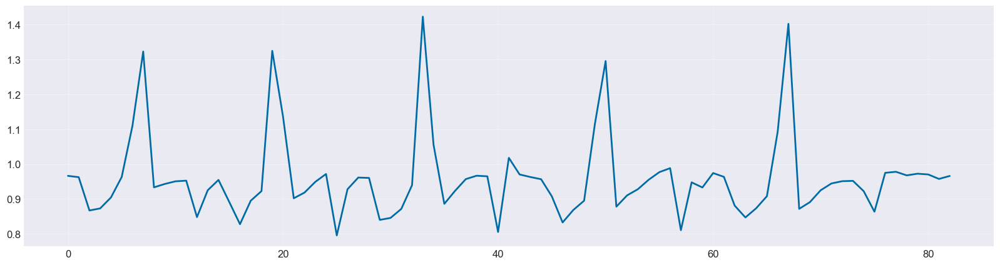

In [199]:
plt.plot(set_df["acc_y"].reset_index(drop=True))

In [200]:
df.label.unique()

array(['bench', 'ohp', 'squat', 'dead', 'row', 'rest'], dtype=object)

In [201]:
df.category.unique()

array(['heavy', 'medium', 'sitting', 'standing'], dtype=object)

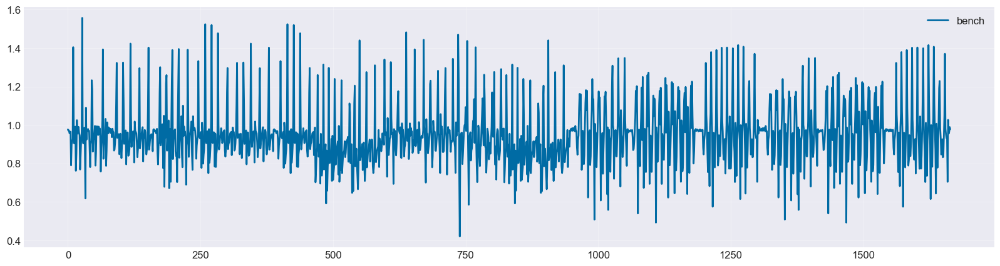

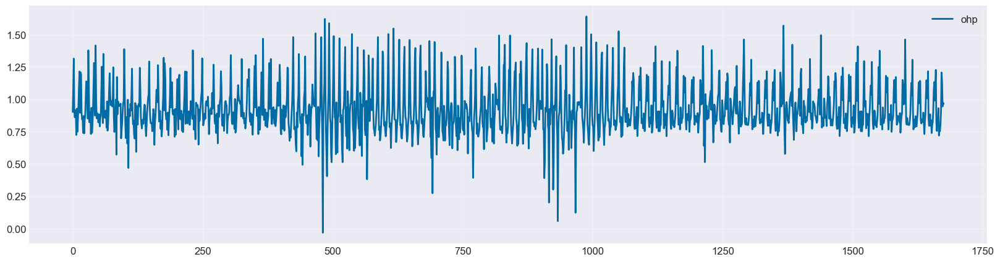

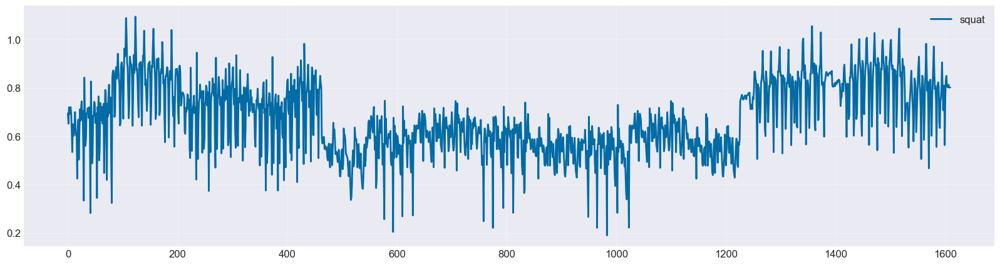

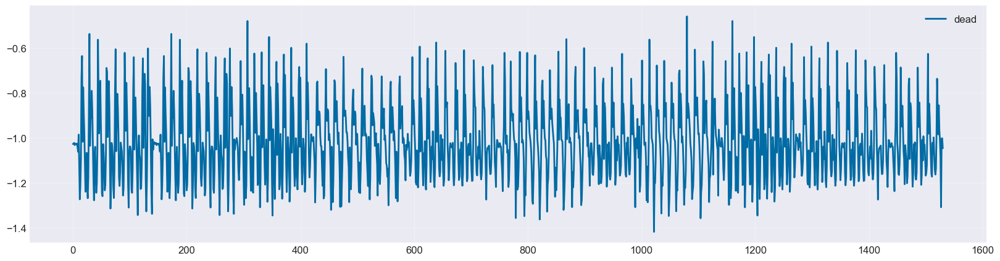

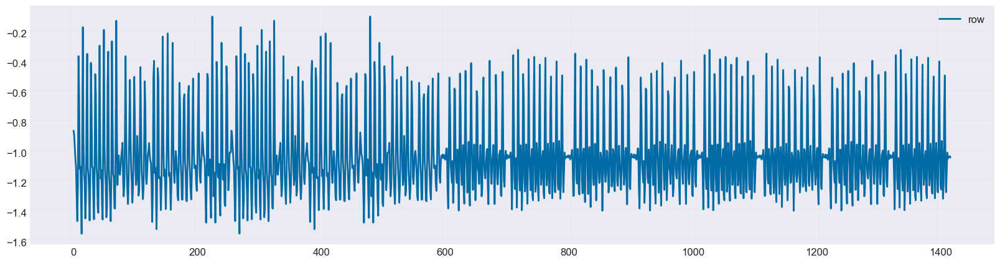

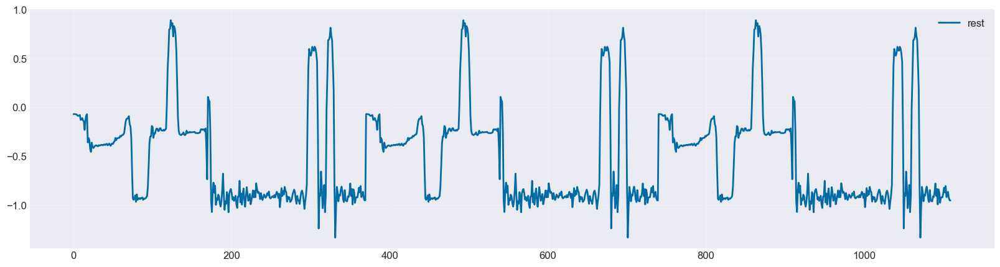

In [202]:
for label in df["label"].unique():
    subset=df[df["label"]==label]
    fig , ax=plt.subplots()
    plt.plot(subset["acc_y"].reset_index(drop=True),label=label)
    plt.legend()
    plt.show()

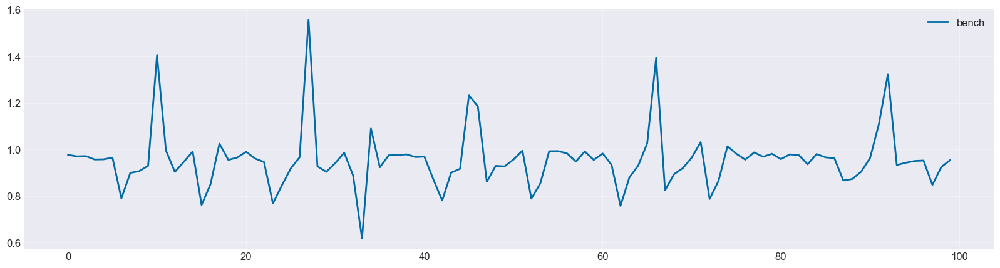

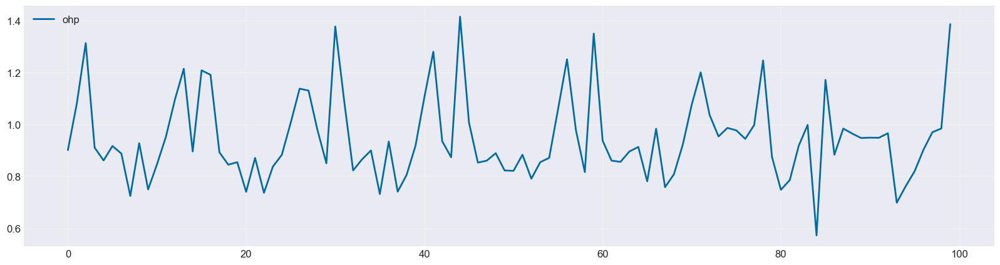

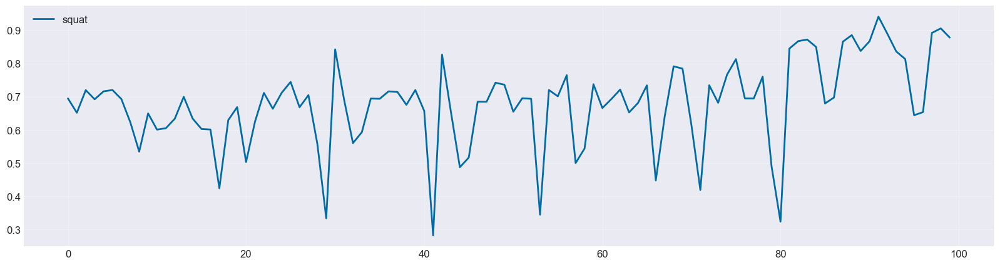

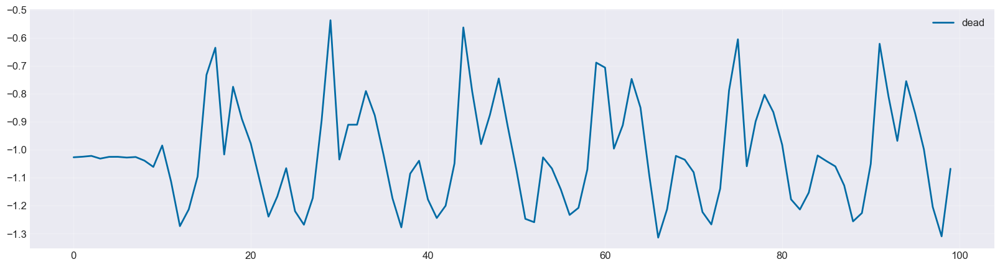

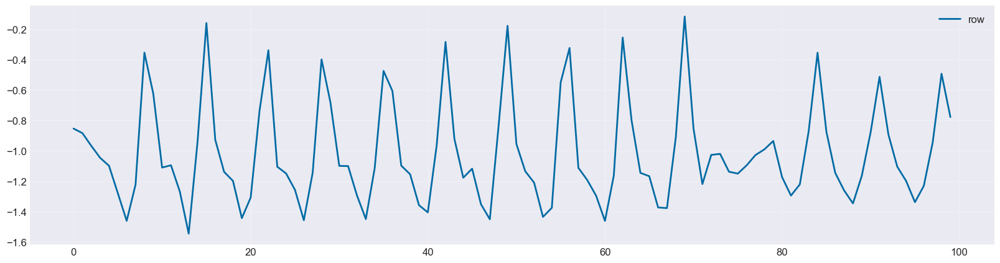

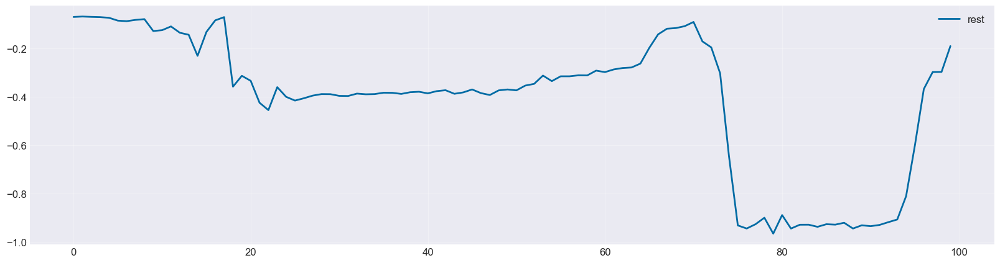

In [203]:
for label in df["label"].unique():
    subset=df[df["label"]==label]
    fig , ax=plt.subplots()
    plt.plot(subset[:100]["acc_y"].reset_index(drop=True),label=label)
    #visuals are getting messy so we use only 100 rows of data 
    plt.legend()
    plt.show()

Text(0, 0.5, 'acc_y')

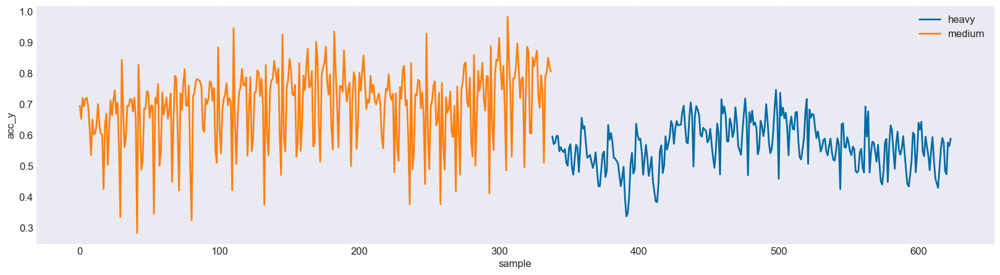

In [204]:
category_df=df.query("label == 'squat'").query("participant=='A'").reset_index()
category_df.groupby(["category"])["acc_y"].plot().reset_index()
plt.legend()
plt.xlabel("sample")
plt.ylabel("acc_y")

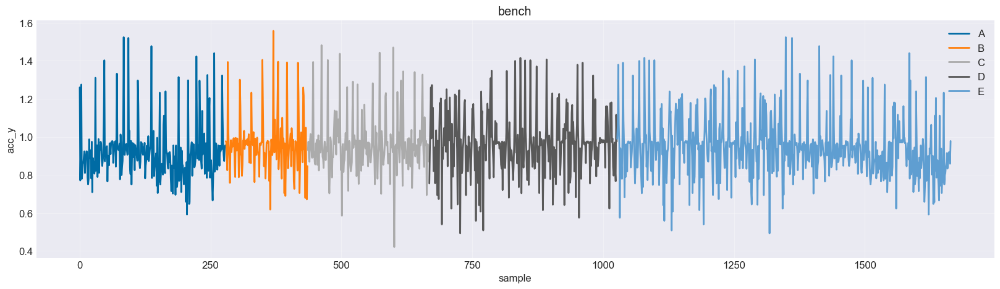

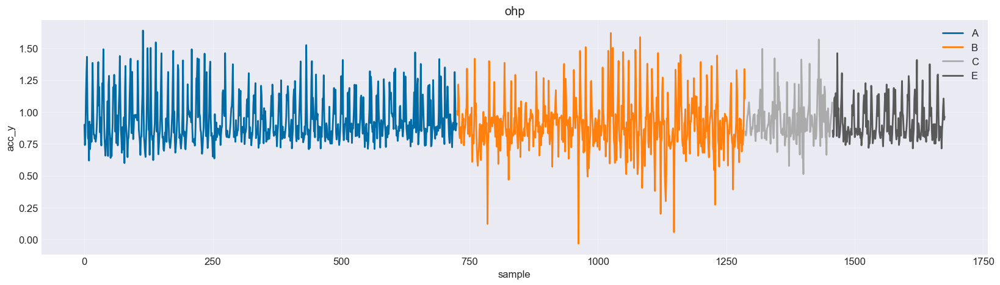

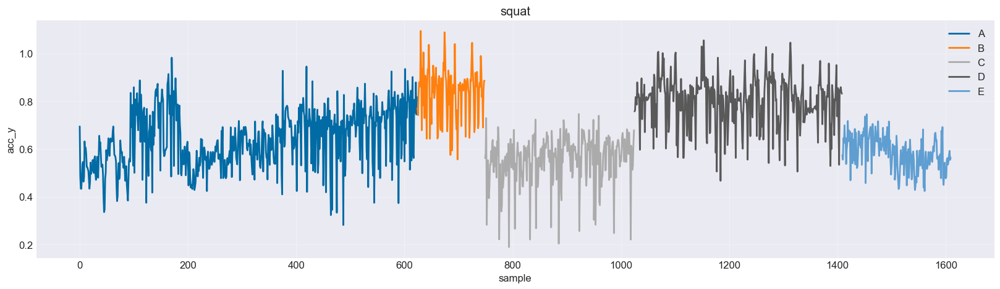

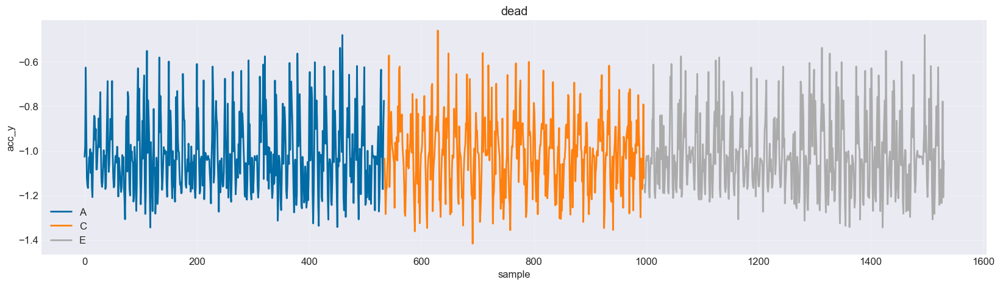

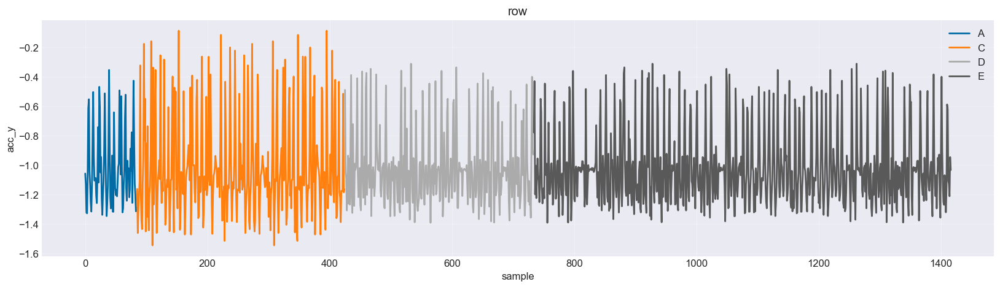

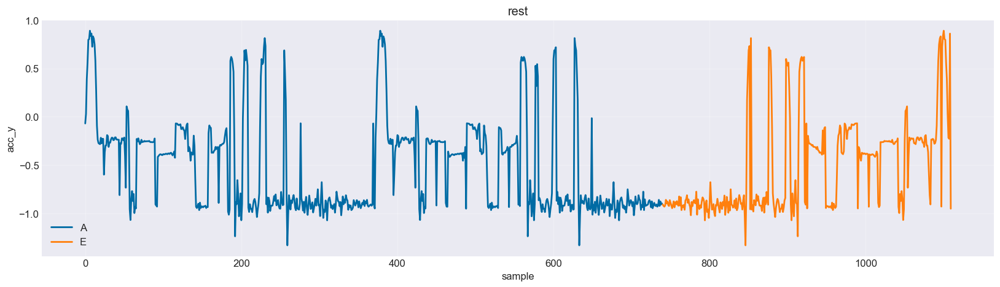

In [220]:
for exercise in df["label"].unique():
    participant_df=df.query("label == @exercise").sort_values("participant").reset_index()
    participant_df.groupby(["participant"])["acc_y"].plot()
    plt.legend()
    plt.title(exercise)
    plt.xlabel("sample")
    plt.ylabel("acc_y")  
    plt.show()
      

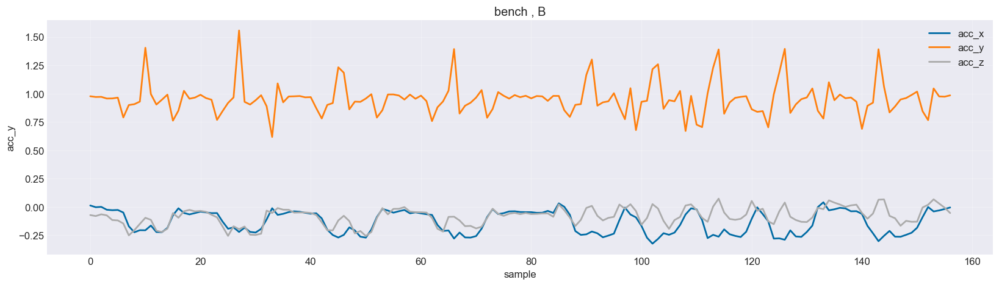

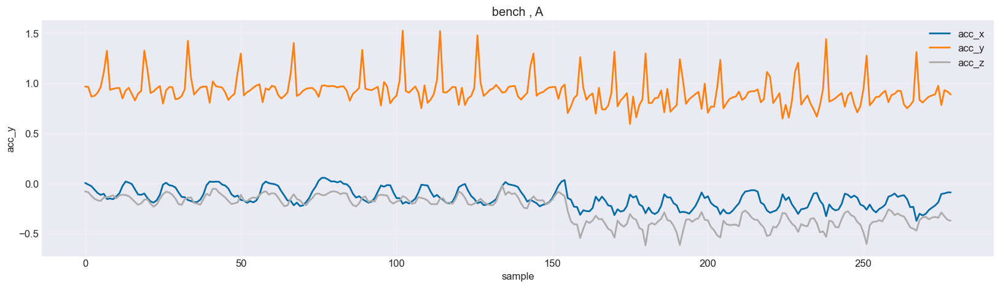

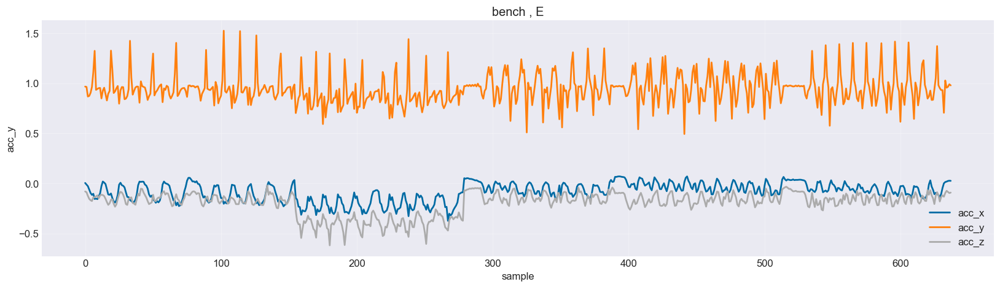

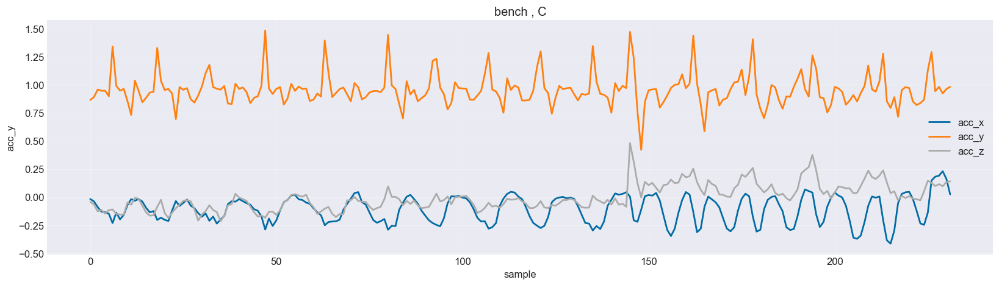

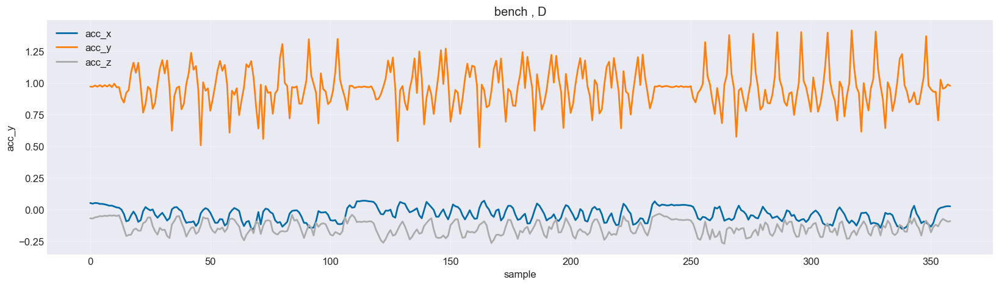

...

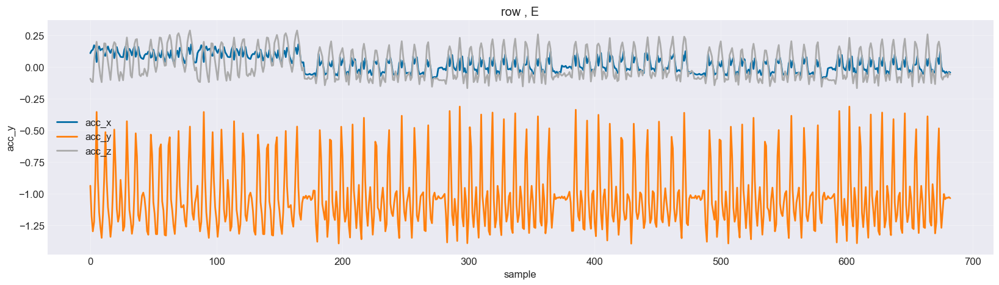

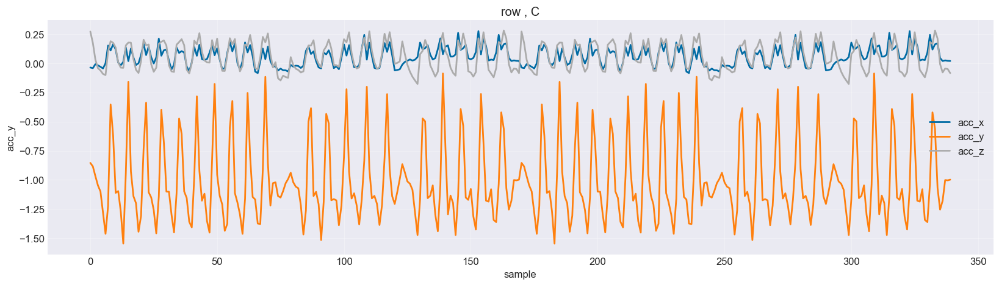

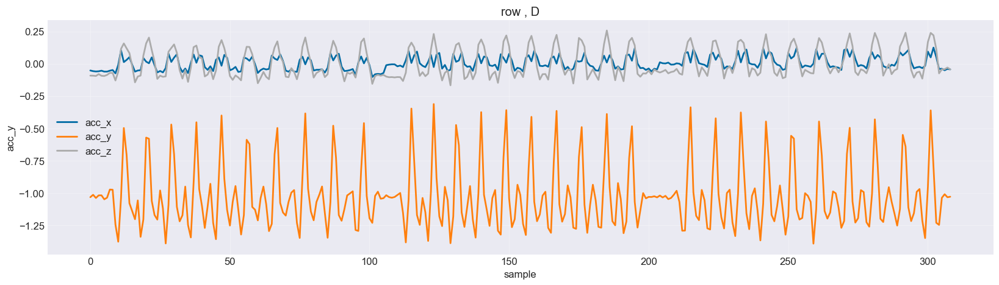

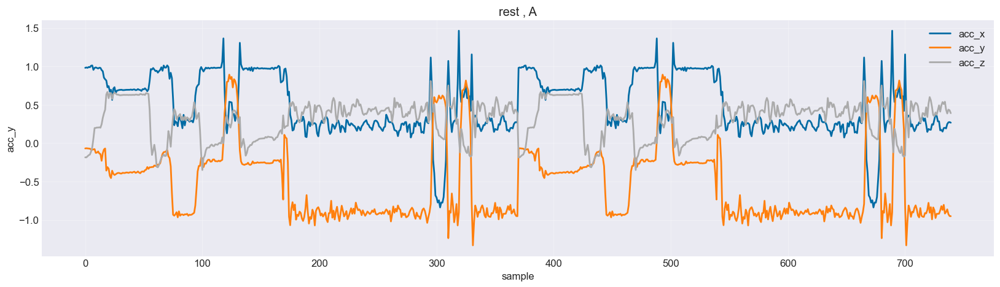

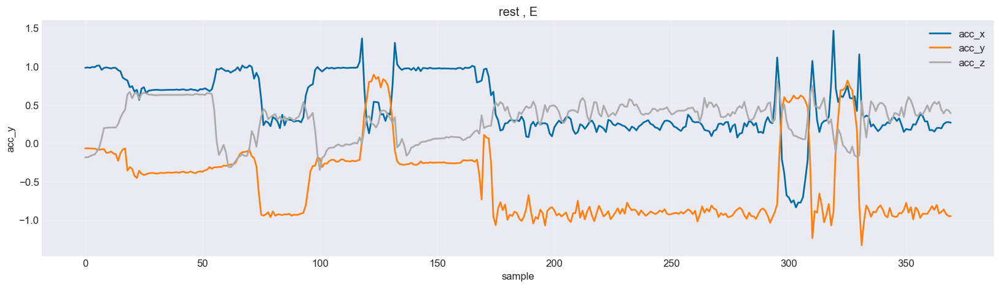

In [ ]:
for label in df["label"].unique():
    for participant in df["participant"].unique():      
      all_axix_data=df.query("label == @label").query("participant == @participant").reset_index()
      if len(all_axix_data) >0:
        fig , ax=plt.subplots()
        all_axix_data[["acc_x","acc_y","acc_z"]].sortplot(ax=ax)
        plt.title(f"{label} , {participant}")
        plt.xlabel("sample")
        plt.ylabel("acc_y")  
        plt.show()
      

In [236]:
#now same we are going to do for gyroscope data.

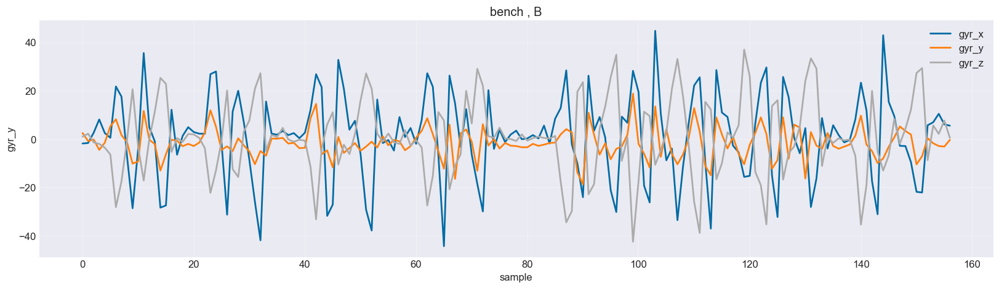

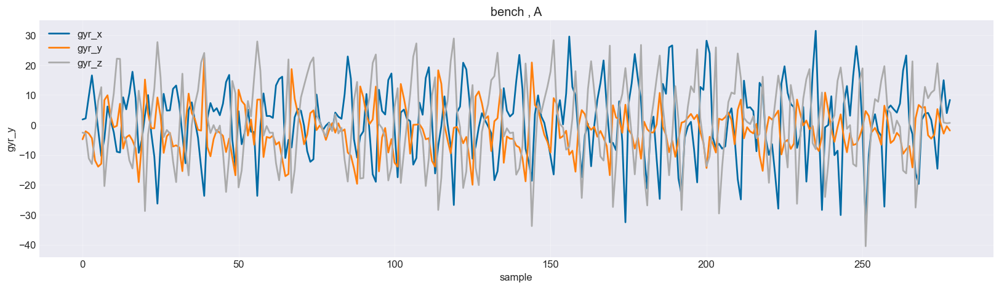

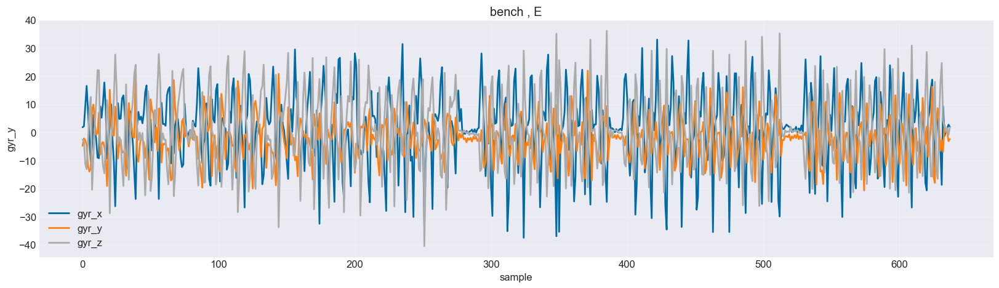

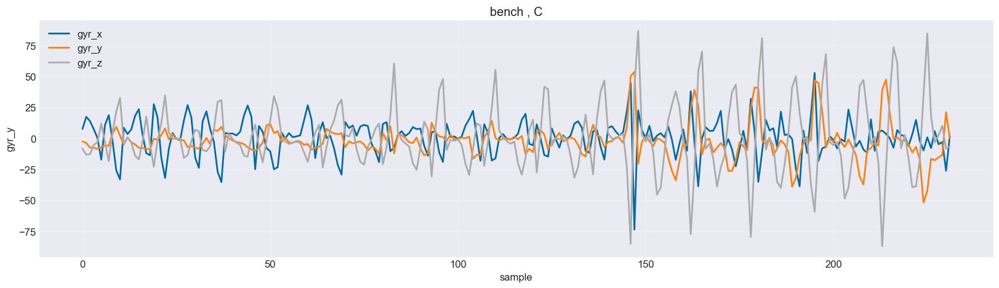

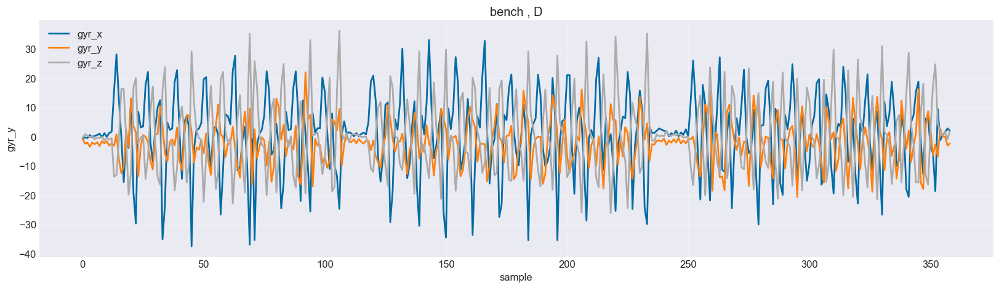

...

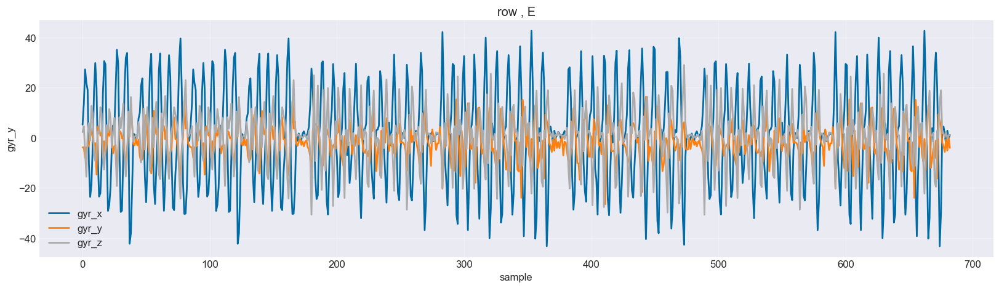

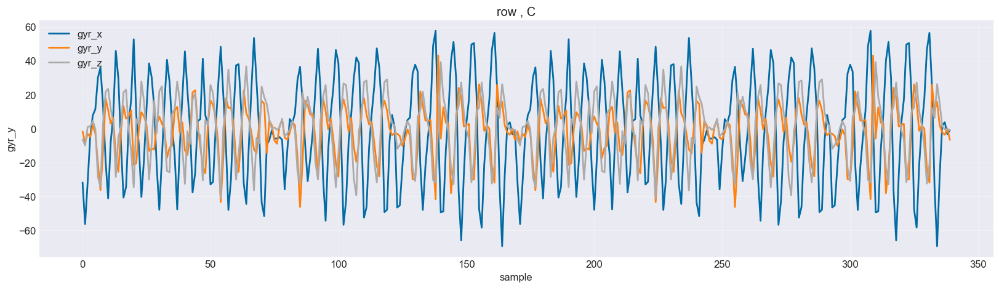

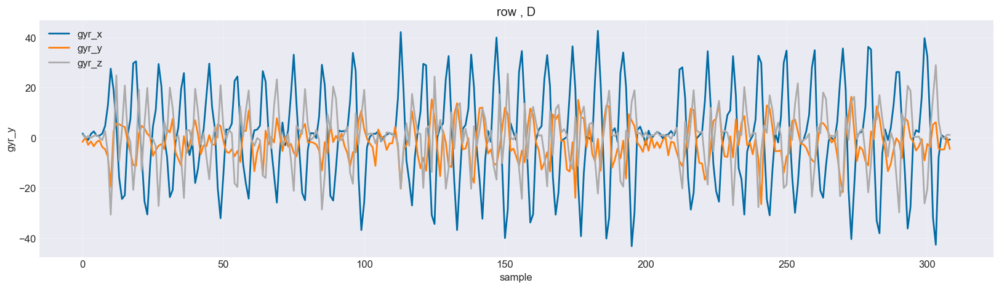

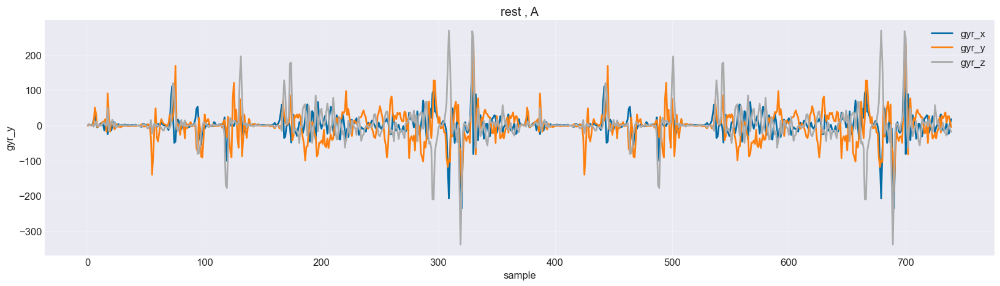

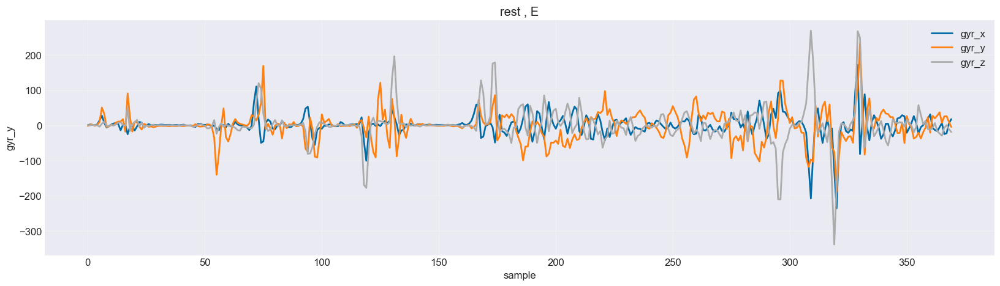

In [ ]:
for label in df["label"].unique():
    for participant in df["participant"].unique():      
      all_axix_data=df.query("label == @label").query("participant == @participant").reset_index()
      if len(all_axix_data) >0:
        fig , ax=plt.subplots()
        all_axix_data[["gyr_ax","gyr_y","gyr_z"]].plot(ax=ax)
        plt.title(f"{label} , {participant}")
        plt.xlabel("sample")
        plt.ylabel("gyr_y")  
        plt.show()
      

In [ ]:
#now i am going to merge both gyroscope and accelerometer data in one visual

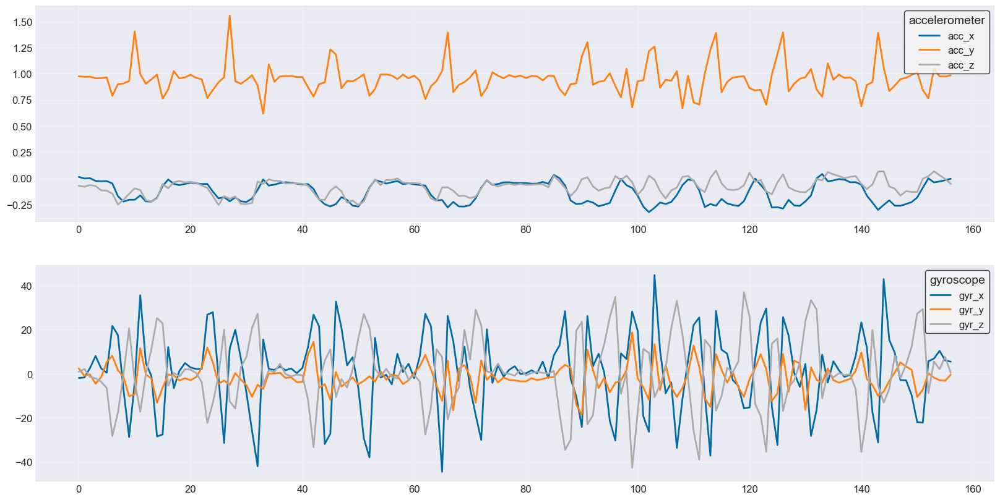

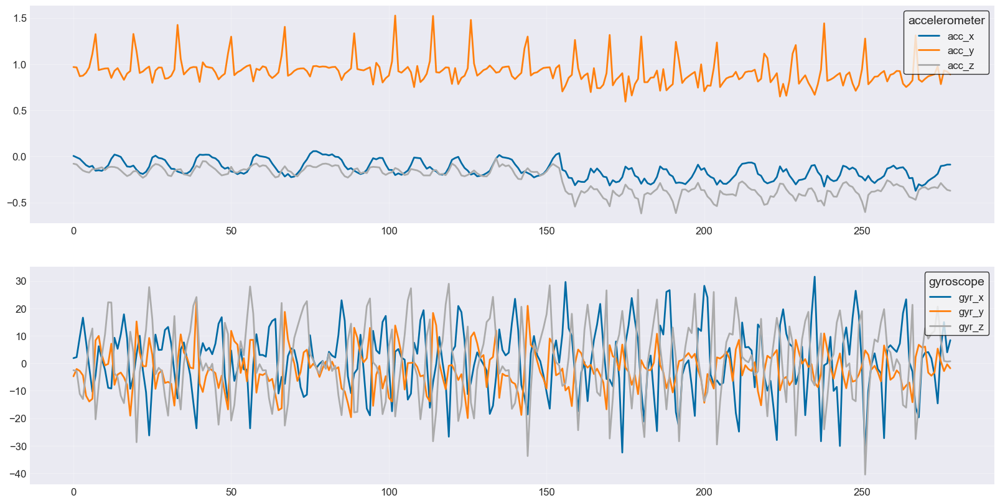

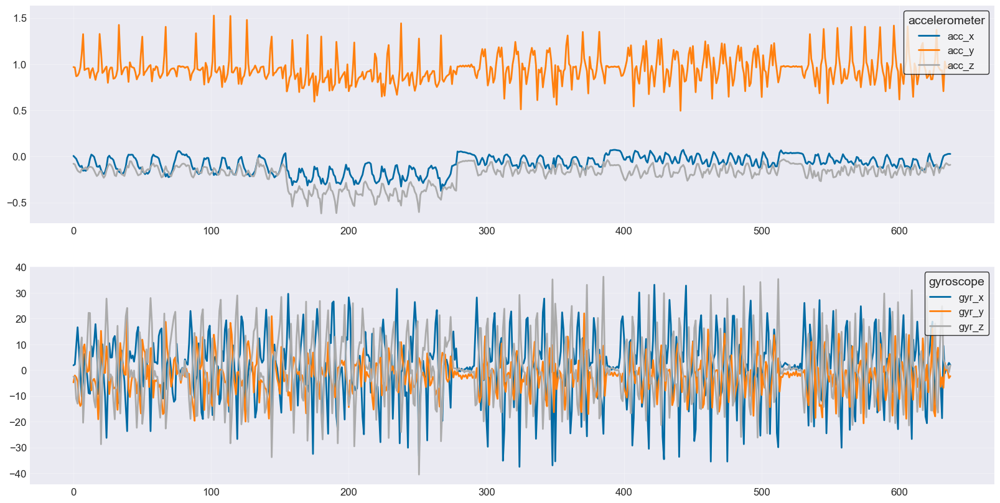

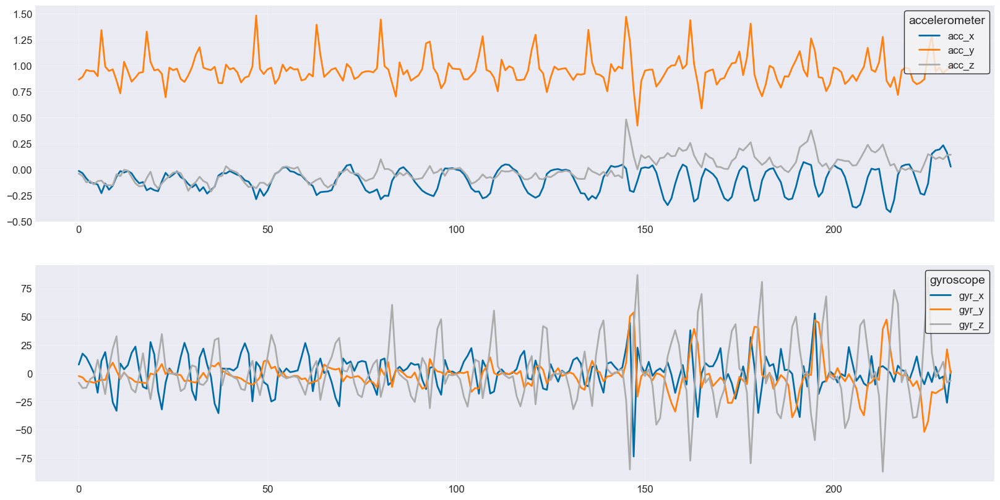

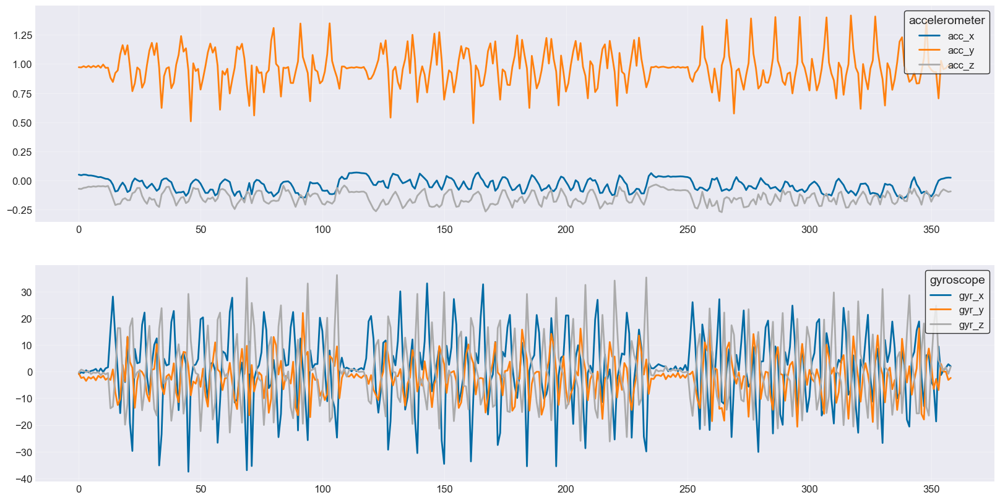

...

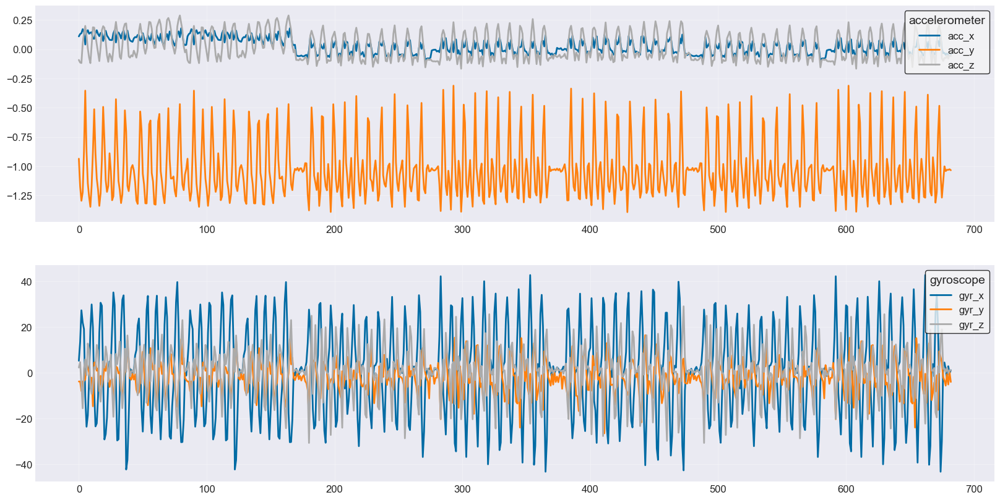

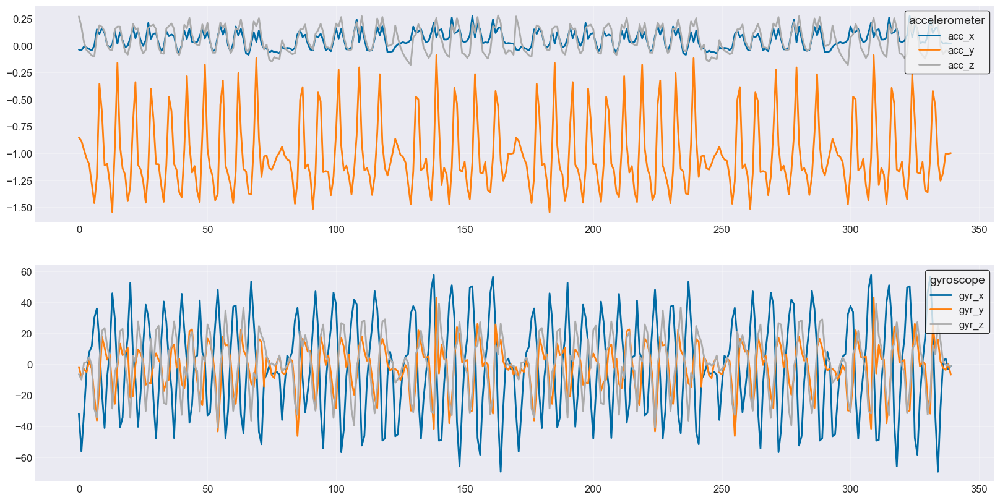

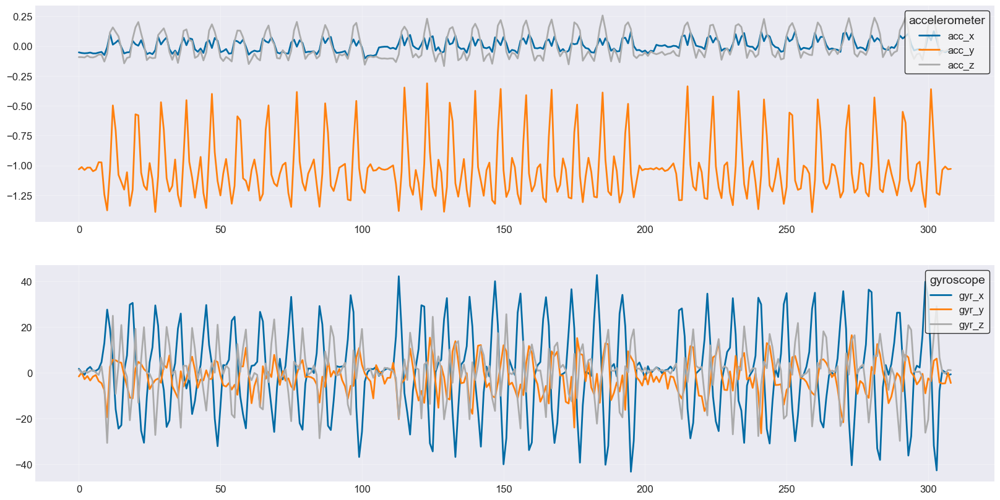

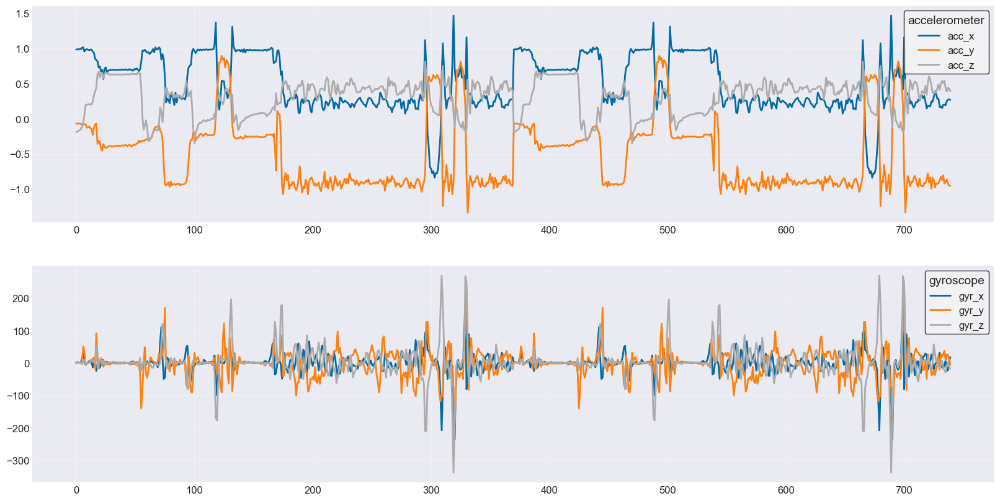

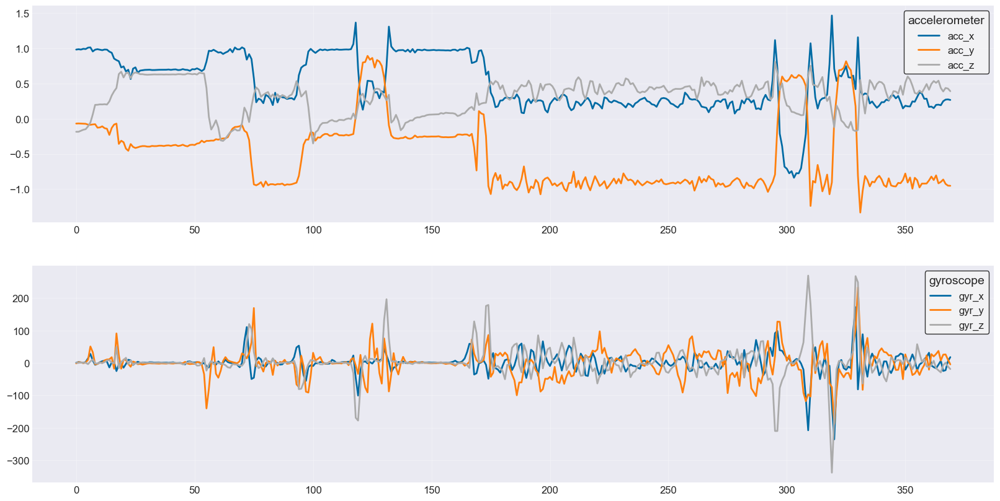

In [248]:
for label in df["label"].unique():
    for participant in df["participant"].unique():      
      combined_data=df.query("label == @label").query("participant == @participant").reset_index(drop=True)
      if len(combined_data)>0:   
         fig , ax=plt.subplots(nrows=2,figsize=(20,10))
         combined_data[["gyr_x","gyr_y","gyr_z"]].plot(ax=ax[1])
         combined_data[["acc_x","acc_y","acc_z"]].plot(ax=ax[0])
         ax[0].legend(loc="upper right",          # Position: 'upper right', 'lower left', 'center', etc.
                   frameon=True,               # Enable/disable the background box
                   facecolor="#f5f5f5",        # Background color of the legend box
                   edgecolor="black",          # Border color of the legend box
                   fontsize=12,                # Text size
                   title="accelerometer",        # Optional legend title
                   title_fontsize=14)
         ax[1].legend(loc="upper right",          # Position: 'upper right', 'lower left', 'center', etc.
                   frameon=True,               # Enable/disable the background box
                   facecolor="#f5f5f5",        # Background color of the legend box
                   edgecolor="black",          # Border color of the legend box
                   fontsize=12,                # Text size
                   title="gyroscope",        # Optional legend title
                   title_fontsize=14)
         plt.savefig(f"../../reports/figures/{label.title()} ({participant}).png")
         plt.show()
      
      